# AQUAVOLTA — Exploratory prediction of export revenue (`CA_TND`)

Last stage of the BI process. The notebook reads the warehouse table `export_d` from MySQL, and evaluates whether the export invoice amount in TND can be predicted from the **country** and the **department** alone, using leave-one-group-out validation and several model families compared against naive baselines.

**Reading guide**

- Database credentials are read from a local `.env` file (see `.env.example`); none is stored here.
- Outputs that displayed real rows (client names, invoice amounts) were removed for publication. Model metrics and charts are kept as executed.
- **Result: no model reliably beats the naive baselines (R² is negative for every candidate).** The work is exploratory; it is not an operational forecast. See `README.md` in this folder.


In [ ]:
# Install once in this Jupyter kernel if needed: %pip install sqlalchemy pymysql python-dotenv pandas numpy scikit-learn matplotlib catboost joblib
import os, pandas as pd, numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL, text
load_dotenv(dotenv_path='.env')
required_env=['MYSQL_HOST','MYSQL_PORT','MYSQL_DATABASE','MYSQL_USER','MYSQL_PASSWORD']
missing_env=[k for k in required_env if os.getenv(k) is None]
if missing_env: raise EnvironmentError(f'Missing keys in .env: {missing_env}')
db_url=URL.create('mysql+pymysql',username=os.environ['MYSQL_USER'],password=os.environ['MYSQL_PASSWORD'],host=os.environ['MYSQL_HOST'],port=int(os.environ['MYSQL_PORT']),database=os.environ['MYSQL_DATABASE'],query={'charset':'utf8mb4'})
engine=create_engine(db_url,pool_pre_ping=True)
with engine.connect() as conn:
    server_version=conn.execute(text('SELECT VERSION()')).scalar_one()
    current_database=conn.execute(text('SELECT DATABASE()')).scalar_one()
    tables=pd.read_sql(text('SELECT TABLE_NAME FROM INFORMATION_SCHEMA.TABLES WHERE TABLE_SCHEMA=:db ORDER BY TABLE_NAME'),conn,params={'db':os.environ['MYSQL_DATABASE']})['TABLE_NAME'].tolist()
print('Connected:',current_database,'|',server_version,'| tables:',tables)


In [ ]:
# Existing read-only table loads; export_d is the project's source table.
query_date='SELECT * FROM date_d'
query_departement='SELECT * FROM departement_d'
query_depense='SELECT * FROM depense_d'
query_encaissement='SELECT * FROM encaissement_d'
query_export='SELECT * FROM export_d'
query_fact_tabel='SELECT * FROM fact_tabel'
query_local='SELECT * FROM local_d'
query_reglement='SELECT * FROM reglement_d'
query_salaire='SELECT * FROM salaire_d'
data_date=pd.read_sql(query_date,engine)
data_departement=pd.read_sql(query_departement,engine)
data_depense=pd.read_sql(query_depense,engine)
data_encaissement=pd.read_sql(query_encaissement,engine)
data_export=pd.read_sql(query_export,engine)
data_fact_tabel=pd.read_sql(query_fact_tabel,engine)
data_local=pd.read_sql(query_local,engine)
data_reglement=pd.read_sql(query_reglement,engine)
data_salaire=pd.read_sql(query_salaire,engine)
print('export_d:',len(data_export),'rows')


In [ ]:
print(data_date)

In [ ]:
print(data_encaissement)

In [ ]:

data_export['CA_TND'] = data_export['CA_TND'].str.replace(',', '.', regex=False).astype(float)
print(data_export.info())

In [ ]:
print(data_export['departement'])

In [ ]:
# Supprimer les espaces et sauts de ligne (\n, \t, etc.)
data_export['departement'] = data_export['departement'].str.strip()

# Vérification
print(data_export['departement'].unique())
print(data_export['departement'])

In [ ]:
print(data_export)

In [ ]:
df_export = data_export[['DATE','PAYS','departement','CA_TND']]
print(df_export)

In [ ]:
# S'assurer que la colonne DATE est bien en datetime
df_export['DATE'] = pd.to_datetime(df_export['DATE'], errors='coerce')

# Créer deux nouvelles colonnes
df_export['ANNEE'] = df_export['DATE'].dt.year
df_export['MOIS']  = df_export['DATE'].dt.month

print(df_export)

In [ ]:
d_export = df_export[['ANNEE','MOIS','PAYS','departement','CA_TND']]
print(d_export)

# Phase 3: advanced audit and final optimization

## Audit trail and data

The live `export_d` read on 2026-11-11 returned 58 observations and 8 normalized PAYS-departement pairs. No target rows were excluded. Counts range from 1 to 12 per pair. `PAYS` and `departement` are the only predictors; `DATE` was used only to report the observed date span, 2022-01-05 through 2023-12-23.

The LOGO structure was checked directly: 8 outer folds, one complete pair per test fold, and no test pair in that fold's training data. One-hot encoders, target transforms, and hyperparameter selection are fitted inside training folds. The phase 2 Extra Trees configuration was replayed on the live source and reproduces its reported scores: MAE 30,212.884 TND, RMSE 38,809.803 TND, R2 -0.055. Metric calculations were independently checked against scikit-learn; the target has no zero values, so MAPE and tolerance accuracies are defined.

The notebook present at the start of this phase did not contain the reported phase 2 LOGO code; its model section still had an older GroupKFold experiment. This phase adds the LOGO replay and records the actual results below. The connection and initial export preparation remain in place, with connection secrets read from `.env`.

## Group variation

The pooled within-pair standard deviation is 36,561 TND. Differences between pair means explain 19.27% of total target variance; most variation remains within the same country-department pair. Largest observed ranges are Belgique/FLUIDE (120,948 TND), Belgique/ELECTRICITE (113,621 TND), and France/GENI CIVIL (111,437 TND). The n=1 and n=2 pairs make fold-level conclusions sensitive to individual rows.

## Three-phase comparison

| Phase / model | MAE (TND) | RMSE (TND) | R2 | Accuracy +/-10% | Macro group MAE (TND) |
|---|---:|---:|---:|---:|---:|
| Phase 1 CatBoost (reported) | 30,534 | 36,685 | 0.057 | 1.7% | not reported |
| Phase 2 Extra Trees (LOGO replay) | 30,213 | 38,810 | -0.055 | 3.4% | 28,924 |
| Phase 3 Extra Trees (expanded nested search) | 30,563 | 39,350 | -0.085 | 10.3% | 28,569 |

Phase 1's scores are not directly comparable to LOGO unless its split protocol matched; the LOGO replay confirms phase 2 exactly. Phase 3 also compared CatBoost, Ridge, partial pooling, Dummy mean/median, raw targets, and log1p targets. Its complete metric and per-group tables print when the final code cell runs.

## Phase 3 candidates and decision

| LOGO candidate | MAE (TND) | RMSE (TND) | R2 | Accuracy +/-5 / +/-10 / +/-15 | Macro group MAE (TND) |
|---|---:|---:|---:|---:|---:|
| Extra Trees, expanded nested search | 30,563 | 39,350 | -0.085 | 5.2% / 10.3% / 13.8% | 28,569 |
| Extra Trees, phase 2 replay | 30,213 | 38,810 | -0.055 | 1.7% / 3.4% / 6.9% | 28,924 |
| CatBoost, nested shallow search | 31,115 | 40,309 | -0.138 | 3.4% / 6.9% / 12.1% | 27,852 |
| Partial-pooling additive | 32,363 | 38,964 | -0.064 | 1.7% / 8.6% / 10.3% | 30,451 |
| Ridge, nested regularization | 33,832 | 41,563 | -0.210 | 1.7% / 3.4% / 10.3% | 30,706 |
| Dummy median | 32,548 | 40,700 | -0.160 | 5.2% / 10.3% / 12.1% | 29,463 |

The final selector requires a candidate to match or improve Dummy median on group-macro MAE, row MAE, RMSE, R2, and +/-10% accuracy, then chooses the lowest row MAE among qualifying models. The expanded Extra Trees model qualifies; CatBoost has the best macro-group MAE but loses to it on row MAE, RMSE, R2, and tolerance accuracy. The selected model is a modest improvement over the reference, not a robust forecasting solution: all LOGO R2 values remain negative, and +/-10% accuracy is only 10.3%.

For the phase 3 Extra Trees model, the largest group errors are Belgique/GENI CIVIL (MAE 50,014 TND), Tunisie/GENI CIVIL (38,830 TND), France/GENI CIVIL (34,095 TND), and France/FLUIDE (33,930 TND). Group MAE standard deviation is 14,108 TND and worst-group MAE is 50,014 TND. CatBoost's worst group is France/GENI CIVIL at 52,557 TND. This variation and the tiny groups limit confidence in rankings.

The final Extra Trees hyperparameters were selected with grouped CV across all available groups (`min_samples_leaf=1`, `max_features=1.0`, log1p target), then refit on all 58 observations. The log transform is inverted in `predire_ca(PAYS, departement)`. The saved artifact was reloaded and its prediction matched the in-memory pipeline. Use the result for exploration only; the two allowed predictors do not explain enough CA variation for dependable forecasts.


Selected Extra Trees OOF residuals have mean +4,055 TND, standard deviation 39,482 TND, median +734 TND, 5th/95th percentiles -55,240/+69,629 TND, and range -66,526 to +106,549 TND. Largest individual absolute errors include Belgique/FLUIDE (+106,549 TND), Belgique/ELECTRICITE (+98,138 TND), Tunisie/GENI CIVIL (+67,375 TND), and low actual CA in Belgique/GENI CIVIL (about -66,526 TND residual). These errors show the model regresses toward category-level averages and misses large within-pair swings.

The preserved Phase 1 CatBoost configuration (400 iterations, depth 2, learning rate 0.04, L2=5) was also rerun under the common LOGO protocol: MAE 34,953.738 TND, RMSE 40,560.401 TND, R2 -0.152, +/-10% accuracy 3.448%, and macro group MAE 33,588.467 TND. Its historical reported Phase 1 metrics (MAE 30,534; R2 0.057) therefore do not reproduce under LOGO and must not be compared as if they used the same validation split.

In [ ]:
# Phase 3: audit, nested LOGO optimization, error stability, and final full-data refit
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from catboost import CatBoostRegressor
from joblib import dump, load
from pathlib import Path
from IPython.display import display, Image

SEED=42
FEATURES=["PAYS","departement"]
TARGET="CA_TND"
# Normalize category spelling; retain all rows with a valid numeric target.
if not set(FEATURES+[TARGET]).issubset(d_export.columns): raise KeyError("Expected PAYS, departement, CA_TND")
d_export=d_export.copy()
for col in FEATURES: d_export[col]=d_export[col].astype("string").str.strip().str.casefold().replace("",pd.NA)
d_export[TARGET]=pd.to_numeric(d_export[TARGET].astype("string").str.replace(",",".",regex=False),errors="coerce")
bad=d_export[TARGET].isna() | ~np.isfinite(d_export[TARGET].astype(float))
print("Rows:",len(d_export),"| invalid targets excluded:",int(bad.sum()))
if bad.any(): print("Excluded indexes:",d_export.index[bad].tolist())
d_export=d_export.loc[~bad].copy()
for col in FEATURES: d_export[col]=d_export[col].fillna("__missing__").astype(str)
# Invariant features and target; no date-derived predictor enters X.
X=d_export[['PAYS','departement']].copy()
y=d_export['CA_TND'].copy()
if (y<0).any(): raise ValueError("Negative CA_TND requires review before log1p evaluation")
groups=X.astype(str).agg("\x1f".join,axis=1).to_numpy()
unique_groups=np.unique(groups)

# Audit group size, within-group variation, between-group variation, and dates descriptively.
print("\nTarget summary:\n",y.describe(percentiles=[.05,.25,.5,.75,.95]))
print("Skew:",round(float(y.skew()),3),"| zeros:",int((y==0).sum()),"| unique pairs:",len(unique_groups))
if "DATE" in df_export:
    dt=pd.to_datetime(df_export.loc[d_export.index,"DATE"],errors="coerce").dropna()
    if len(dt): print("DATE descriptive range:",dt.min().date(),"to",dt.max().date())
group_stats=(pd.DataFrame({"PAYS":X.PAYS.to_numpy(),"departement":X.departement.to_numpy(),"CA":y.to_numpy(dtype=float)})
    .groupby(["PAYS","departement"],dropna=False).CA.agg(n="size",mean="mean",median="median",std="std",min="min",max="max").reset_index())
group_stats["range"]=group_stats["max"]-group_stats["min"]
group_stats["cv_pct"]=100*group_stats["std"]/group_stats["mean"].abs()
print("\nGroup distributions:\n",group_stats.round(2).to_string(index=False))
within_ss=float(((group_stats.n-1)*group_stats["std"].fillna(0)**2).sum())
mu=float(y.mean()); between_ss=float((group_stats.n*(group_stats["mean"]-mu)**2).sum()); total_ss=float(((y-mu)**2).sum())
pooled_within_sd=(within_ss/max(len(y)-len(group_stats),1))**.5
print("Group sizes:",group_stats.n.value_counts().sort_index().to_dict(),"| pooled within SD:",round(pooled_within_sd,2),"| between-group variance share:",round(between_ss/total_ss,4))

# Explicitly verify each outer fold holds out exactly one pair with no group overlap.
outer=list(LeaveOneGroupOut().split(X,y,groups))
assert len(outer)==len(unique_groups)
for tr,te in outer:
    assert len(np.unique(groups[te]))==1 and not np.isin(groups[te],groups[tr]).any()
print("LOGO verified:",len(outer),"folds; one complete category pair held out per fold.")
USE_LOG=bool(y.min()>=0 and y.skew()>.5)
transforms=[False,True] if USE_LOG else [False]
print("log1p sensitivity candidates:",transforms,"(skewness",round(float(y.skew()),3),")")

# Fold-local one-hot pipelines. ExtraTrees interactions are learned from PAYS/departement only.
def pipeline(kind,params):
    cat=Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("ohe",OneHotEncoder(handle_unknown="ignore"))])
    prep=ColumnTransformer([("cat",cat,FEATURES)],remainder="drop")
    if kind=="ET":
        est=ExtraTreesRegressor(n_estimators=120,min_samples_leaf=params["leaf"],max_features=params["max_features"],random_state=SEED,n_jobs=1)
        return Pipeline([("prep",prep),("model",est)])
    if kind=="RIDGE":
        return Pipeline([("prep",prep),("scale",StandardScaler(with_mean=False)),("model",Ridge(alpha=params["alpha"]))])
    raise ValueError(kind)

def fit_pred(est,Xtr,ytr,Xte,log_target=False,cat=False):
    target=np.log1p(np.asarray(ytr,dtype=float)) if log_target else np.asarray(ytr,dtype=float)
    if cat: est.fit(Xtr,target,cat_features=FEATURES)
    else: est.fit(Xtr,target)
    p=np.asarray(est.predict(Xte),dtype=float)
    if log_target: p=np.expm1(p)
    return np.maximum(p,0.)

def macro_mae(a,p,g):
    z=pd.DataFrame({"actual":np.asarray(a,dtype=float),"pred":np.asarray(p,dtype=float),"group":np.asarray(g)})
    return float(z.groupby("group").apply(lambda q:mean_absolute_error(q.actual,q.pred),include_groups=False).mean())

preds={}; fold_configs={}
def nested_search(label,kind,candidates):
    oof=np.full(len(y),np.nan); chosen=[]
    for fold,(tr,te) in enumerate(outer,1):
        xt=X.iloc[tr].reset_index(drop=True); yt=y.iloc[tr].reset_index(drop=True); gt=groups[tr]
        inner=GroupKFold(n_splits=min(3,len(np.unique(gt))))
        scores=[]
        for cfg in candidates:
            ip=np.full(len(tr),np.nan)
            for itr,iva in inner.split(xt,yt,gt):
                if kind=="CAT":
                    est=CatBoostRegressor(iterations=100,depth=cfg["params"]["depth"],learning_rate=.04,l2_leaf_reg=5,loss_function="RMSE",verbose=False,random_seed=SEED,allow_writing_files=False,thread_count=1)
                else: est=pipeline(kind,cfg["params"])
                ip[iva]=fit_pred(est,xt.iloc[itr],yt.iloc[itr],xt.iloc[iva],cfg["log1p"],kind=="CAT")
            scores.append((macro_mae(yt,ip,gt),cfg))
        score,cfg=min(scores,key=lambda z:z[0])
        if kind=="CAT":
            est=CatBoostRegressor(iterations=100,depth=cfg["params"]["depth"],learning_rate=.04,l2_leaf_reg=5,loss_function="RMSE",verbose=False,random_seed=SEED,allow_writing_files=False,thread_count=1)
        else: est=pipeline(kind,cfg["params"])
        oof[te]=fit_pred(est,X.iloc[tr],y.iloc[tr],X.iloc[te],cfg["log1p"],kind=="CAT")
        chosen.append({"fold":fold,"held_group":unique_groups[fold-1],"inner_macro_MAE":score,"log1p":cfg["log1p"],**cfg["params"]})
    preds[label]=oof; fold_configs[label]=chosen
    print("\n",label,"nested fold choices:\n",pd.DataFrame(chosen).to_string(index=False))

# Phase 2 search replay, followed by a small predeclared ExtraTrees search.
phase2_et=[{"params":{"leaf":l,"max_features":1.0},"log1p":t} for l in [2,4] for t in transforms]
phase3_et=[{"params":{"leaf":l,"max_features":m},"log1p":t} for l in [1,2,4,8] for m in [.7,1.0] for t in transforms]
ridge_cfg=[{"params":{"alpha":a},"log1p":t} for a in [1.,10.,100.] for t in transforms]
cat_cfg=[{"params":{"depth":d},"log1p":t} for d in [2,3] for t in transforms]
nested_search("ExtraTrees_phase2_replay","ET",phase2_et)
nested_search("ExtraTrees_phase3_tuned","ET",phase3_et)
# Re-evaluate the preserved Phase 1 CatBoost configuration using the same external LOGO folds.
# The preserved artifact confirms iterations=400, depth=2, learning_rate=0.04, l2_leaf_reg=5.
phase1_oof=np.full(len(y),np.nan)
for tr,te in outer:
    m=CatBoostRegressor(iterations=400,depth=2,learning_rate=.04,l2_leaf_reg=5,loss_function="RMSE",verbose=False,random_seed=SEED,allow_writing_files=False,thread_count=1)
    m.fit(X.iloc[tr],y.iloc[tr],cat_features=FEATURES)
    phase1_oof[te]=np.maximum(m.predict(X.iloc[te]),0.)
preds["CatBoost_phase1_fixed"]=phase1_oof
nested_search("Ridge_nested","RIDGE",ridge_cfg)
nested_search("CatBoost_nested","CAT",cat_cfg)

# Partial pooling: country and department marginal effects are shrunk toward the training global mean.
def pooled_predict(tr,te,shrink):
    z=pd.DataFrame({"c":X.iloc[tr].PAYS.to_numpy(),"d":X.iloc[tr].departement.to_numpy(),"y":y.iloc[tr].to_numpy(dtype=float)})
    mean=float(z.y.mean()); cm=z.groupby("c").y.mean().to_dict(); dm=z.groupby("d").y.mean().to_dict()
    out=[]
    for i in te:
        c,d=X.iloc[i].PAYS,X.iloc[i].departement
        out.append(max(0.,mean+shrink*(cm.get(c,mean)-mean)+shrink*(dm.get(d,mean)-mean)))
    return np.asarray(out)
shrink_candidates=[.25,.5,.75,1.0]
p=np.full(len(y),np.nan); shrink_choices=[]
for fold,(tr,te) in enumerate(outer,1):
    gt=groups[tr]; inner=GroupKFold(n_splits=min(3,len(np.unique(gt)))); options=[]
    for lam in shrink_candidates:
        ip=np.full(len(tr),np.nan)
        for itr,iva in inner.split(X.iloc[tr].reset_index(drop=True),y.iloc[tr].reset_index(drop=True),gt):
            ip[iva]=pooled_predict(tr[itr],tr[iva],lam)
        options.append((macro_mae(y.iloc[tr],ip,gt),lam))
    score,lam=min(options)
    p[te]=pooled_predict(tr,te,lam)
    shrink_choices.append({"fold":fold,"held_group":unique_groups[fold-1],"shrink":lam,"inner_macro_MAE":score})
preds["Partial_pooling_additive"]=p; fold_configs["Partial_pooling_additive"]=shrink_choices
print("\nPartial-pooling fold choices:\n",pd.DataFrame(shrink_choices).to_string(index=False))

# OOF Dummy references, always fitted on the corresponding outer training fold.
for strategy in ["mean","median"]:
    p=np.full(len(y),np.nan)
    for tr,te in outer: p[te]=DummyRegressor(strategy=strategy).fit(X.iloc[tr],y.iloc[tr]).predict(X.iloc[te])
    preds["Dummy_"+strategy]=p

# Recalculate standard and business metrics independently; group macro MAE and dispersion measure stability.
def metric(a,p):
    a=np.asarray(a,dtype=float); p=np.asarray(p,dtype=float); nz=a!=0; den=np.abs(a)+np.abs(p); sm=den>0
    return {"MAE_TND":mean_absolute_error(a,p),"RMSE_TND":mean_squared_error(a,p)**.5,"R2":r2_score(a,p),
      "Acc_5_pct":100*np.mean(np.abs(a[nz]-p[nz])<=.05*np.abs(a[nz])) if nz.any() else np.nan,
      "Acc_10_pct":100*np.mean(np.abs(a[nz]-p[nz])<=.1*np.abs(a[nz])) if nz.any() else np.nan,
      "Acc_15_pct":100*np.mean(np.abs(a[nz]-p[nz])<=.15*np.abs(a[nz])) if nz.any() else np.nan,
      "MAPE_pct":100*np.mean(np.abs((a[nz]-p[nz])/a[nz])) if nz.any() else np.nan,
      "SMAPE_pct":100*np.mean(2*np.abs(a[sm]-p[sm])/den[sm]) if sm.any() else np.nan}
rows=[]; errors=[]
for name,p in preds.items():
    z=pd.DataFrame({"group":groups,"actual":y.to_numpy(dtype=float),"pred":p})
    gm=z.groupby("group").apply(lambda q:mean_absolute_error(q.actual,q.pred),include_groups=False)
    rows.append({"Model":name,**metric(y,p),"Macro_group_MAE":gm.mean(),"SD_group_MAE":gm.std(ddof=0),"Worst_group_MAE":gm.max()})
    for key,q in z.groupby("group"):
        idx=np.flatnonzero(groups==key)[0]
        errors.append({"Model":name,"PAYS":X.iloc[idx].PAYS,"departement":X.iloc[idx].departement,"n":len(q),"MAE_TND":mean_absolute_error(q.actual,q.pred),"RMSE_TND":mean_squared_error(q.actual,q.pred)**.5,"Bias_real_minus_pred":float((q.actual-q.pred).mean())})
comparison=pd.DataFrame(rows).sort_values(["Macro_group_MAE","MAE_TND"]).reset_index(drop=True)
per_group=pd.DataFrame(errors)
print("\n--- LOGO comparison (ranked by macro-group MAE) ---\n",comparison.round(3).to_string(index=False))
print("\n--- Per-group errors for key candidates ---\n",per_group[per_group.Model.isin(["Dummy_median","CatBoost_phase1_fixed","ExtraTrees_phase2_replay","ExtraTrees_phase3_tuned","Ridge_nested","CatBoost_nested","Partial_pooling_additive"])].round(2).to_string(index=False))

# Required global comparison table; charts are rendered in four separate cells below.
model_labels={"Dummy_median":"Dummy Median","Dummy_mean":"Dummy Mean","CatBoost_phase1_fixed":"CatBoost Phase 1 (LOGO)","ExtraTrees_phase2_replay":"Extra Trees Phase 2","ExtraTrees_phase3_tuned":"Extra Trees Phase 3","CatBoost_nested":"CatBoost Nested","Ridge_nested":"Ridge Nested","Partial_pooling_additive":"Partial Pooling"}
comparison["Display_Model"]=comparison.Model.map(model_labels).fillna(comparison.Model)
global_table=comparison[["Display_Model","MAE_TND","RMSE_TND","R2","Acc_10_pct","Macro_group_MAE"]].rename(columns={"Display_Model":"Model","MAE_TND":"MAE (TND)","RMSE_TND":"RMSE (TND)","Acc_10_pct":"Accuracy +/-10%","Macro_group_MAE":"Mean Group MAE (TND)"})
print("\n--- Global OOF comparison table ---\n",global_table.round(3).to_string(index=False))
chart_order=["Dummy_median","CatBoost_phase1_fixed","ExtraTrees_phase2_replay","ExtraTrees_phase3_tuned","CatBoost_nested","Ridge_nested","Partial_pooling_additive","Dummy_mean"]
chart_order=[name for name in chart_order if name in comparison.Model.to_list()]
def render_metric_chart(metric_name,ylabel,title,filename,higher_is_better):
    plot_rows=comparison.set_index("Model").loc[chart_order].reset_index(); values=plot_rows[metric_name].to_numpy(dtype=float)
    best_value=float(np.nanmax(values) if higher_is_better else np.nanmin(values)); best_positions=np.flatnonzero(np.isclose(values,best_value,rtol=1e-9,atol=1e-9)); fig,ax=plt.subplots(figsize=(max(10,1.55*len(chart_order)),6)); xx=np.arange(len(chart_order))
    ax.plot(xx,values,marker="o",linewidth=2,color="#2878B5"); ax.scatter(best_positions,values[best_positions],s=150,marker="*",color="#D1495B",zorder=3,label="Best on metric (ties shown)")
    for j,v in enumerate(values): ax.annotate(f"{v:.3f}",(j,v),xytext=(0,9 if v<np.nanmax(values) else -18),textcoords="offset points",ha="center",fontsize=9)
    if metric_name=="R2": ax.axhline(0,color="black",linewidth=1,linestyle="--",label="R2 = 0")
    ax.set_xticks(xx,[model_labels.get(n,n) for n in chart_order],rotation=25,ha="right"); ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(True,alpha=.25); ax.legend(); fig.tight_layout()
    chart_path=Path.cwd()/filename; fig.savefig(chart_path,dpi=160,bbox_inches="tight"); display(Image(filename=str(chart_path))); plt.close(fig); print("Chart saved:",chart_path)

# Reconcile phase 2 reference and verify metric implementation.
replay=metric(y,preds["ExtraTrees_phase2_replay"])
assert abs(replay["MAE_TND"]-mean_absolute_error(y.to_numpy(dtype=float),preds["ExtraTrees_phase2_replay"]))<1e-9
print("Phase 2 reported ExtraTrees: MAE 30,213; RMSE 38,810; R2 -0.055. Recomputed replay:", {k:round(v,3) for k,v in replay.items() if k in ["MAE_TND","RMSE_TND","R2","Acc_10_pct"]})

# Multi-metric decision: qualify only candidates that do not regress the Dummy-median baseline
# on group-macro MAE, row MAE, RMSE, R2, or +/-10% accuracy. Then rank qualified models by row MAE.
base=comparison.loc[comparison.Model=="Dummy_median"].iloc[0]
eligible_names=["ExtraTrees_phase2_replay","ExtraTrees_phase3_tuned","Ridge_nested","CatBoost_nested","Partial_pooling_additive"]
qualified=comparison[comparison.Model.isin(eligible_names) &
    (comparison.Macro_group_MAE<=base.Macro_group_MAE) &
    (comparison.MAE_TND<=base.MAE_TND) & (comparison.RMSE_TND<=base.RMSE_TND) &
    (comparison.R2>=base.R2) & (comparison.Acc_10_pct>=base.Acc_10_pct)]
if len(qualified):
    best=str(qualified.sort_values(["MAE_TND","Macro_group_MAE"]).iloc[0].Model)
    print("\nMulti-metric qualified candidates:\n",qualified[["Model","MAE_TND","RMSE_TND","R2","Acc_10_pct","Macro_group_MAE"]].round(3).to_string(index=False))
else:
    best="Dummy_median"
print("\nFinal selection after baseline checks:",best)
selected_residual=y.to_numpy(dtype=float)-preds[best]
print("Selected model residual distribution (actual - OOF prediction):\n",pd.Series(selected_residual).describe(percentiles=[.05,.25,.5,.75,.95]).round(2).to_dict())
print("Largest absolute row errors:\n",pd.DataFrame({"PAYS":X.PAYS,"departement":X.departement,"actual_TND":y,"predicted_OOF_TND":preds[best],"residual_TND":selected_residual}).assign(abs_error=lambda z:z.residual_TND.abs()).nlargest(10,"abs_error").round(2).to_string(index=False))
print("Eight groups only; candidate selection on LOGO scores still carries selection optimism.")

# Select final hyperparameters on all groups with grouped CV, then refit on all 58 observations.
kind_by_name={"ExtraTrees_phase2_replay":("ET",phase2_et),"ExtraTrees_phase3_tuned":("ET",phase3_et),"Ridge_nested":("RIDGE",ridge_cfg),"CatBoost_nested":("CAT",cat_cfg)}
if best in kind_by_name:
    kind,candidates=kind_by_name[best]; cv=GroupKFold(n_splits=min(4,len(unique_groups))); options=[]
    for cfg in candidates:
        q=np.full(len(y),np.nan)
        for tr,te in cv.split(X,y,groups):
            if kind=="ET": est=pipeline(kind,cfg["params"])
            elif kind=="RIDGE": est=pipeline(kind,cfg["params"])
            else: est=CatBoostRegressor(iterations=100,depth=cfg["params"]["depth"],learning_rate=.04,l2_leaf_reg=5,loss_function="RMSE",verbose=False,random_seed=SEED,allow_writing_files=False,thread_count=1)
            q[te]=fit_pred(est,X.iloc[tr],y.iloc[tr],X.iloc[te],cfg["log1p"],kind=="CAT")
        options.append((macro_mae(y,q,groups),cfg))
    _,final_cfg=min(options,key=lambda z:z[0]); print("Full-data grouped CV final config:",final_cfg)
    if kind=="CAT": final_model=CatBoostRegressor(iterations=100,depth=final_cfg["params"]["depth"],learning_rate=.04,l2_leaf_reg=5,loss_function="RMSE",verbose=False,random_seed=SEED,allow_writing_files=False,thread_count=1); final_model.fit(X,np.log1p(y) if final_cfg["log1p"] else y,cat_features=FEATURES)
    else: final_model=pipeline(kind,final_cfg["params"]); final_model.fit(X,np.log1p(y) if final_cfg["log1p"] else y)
    if kind=="CAT": final_model.save_model("meilleur_modele_final_executed.cbm")
    else: dump({"model":final_model,"log1p":final_cfg["log1p"],"kind":kind,"params":final_cfg["params"],"features":FEATURES,"fit_rows":len(y)},"meilleur_modele_final_executed.joblib")
    def predire_ca(PAYS,departement):
        row=pd.DataFrame([[str(PAYS).strip().casefold(),str(departement).strip().casefold()]],columns=FEATURES)
        v=float(final_model.predict(row)[0]); return float(max(0.,np.expm1(v))) if final_cfg["log1p"] else float(max(0.,v))
elif best=="Partial_pooling_additive":
    cv=GroupKFold(n_splits=min(4,len(unique_groups))); options=[]
    for lam in shrink_candidates:
        q=np.full(len(y),np.nan)
        for tr,te in cv.split(X,y,groups): q[te]=pooled_predict(tr,te,lam)
        options.append((macro_mae(y,q,groups),lam))
    _,final_shrink=min(options); all_data=pd.DataFrame({"c":X.PAYS,"d":X.departement,"y":y}); final_mu=float(y.mean()); final_cm=all_data.groupby("c").y.mean().to_dict(); final_dm=all_data.groupby("d").y.mean().to_dict()
    dump({"strategy":best,"shrink":final_shrink,"mean":final_mu,"country":final_cm,"department":final_dm},"meilleur_modele_final_executed.joblib")
    def predire_ca(PAYS,departement):
        c=str(PAYS).strip().casefold(); d=str(departement).strip().casefold(); return float(max(0.,final_mu+final_shrink*(final_cm.get(c,final_mu)-final_mu)+final_shrink*(final_dm.get(d,final_mu)-final_mu)))
else:
    final_strategy="median" if best=="Dummy_median" else "mean"; final_value=float(y.median() if final_strategy=="median" else y.mean()); dump({"strategy":"Dummy_"+final_strategy,"value":final_value},"meilleur_modele_final_executed.joblib")
    def predire_ca(PAYS,departement): return final_value

# Reload the artifact and verify the same two-input prediction after final all-data fit.
example=float(predire_ca(X.iloc[0].PAYS,X.iloc[0].departement))
assert np.isfinite(example)
if best in kind_by_name:
    if kind=="CAT":
        reloaded=CatBoostRegressor(); reloaded.load_model("meilleur_modele_final_executed.cbm")
        raw=float(reloaded.predict(pd.DataFrame([[X.iloc[0].PAYS,X.iloc[0].departement]],columns=FEATURES))[0]); check=float(max(0.,np.expm1(raw))) if final_cfg["log1p"] else float(max(0.,raw))
    else:
        info=load("meilleur_modele_final_executed.joblib"); reloaded=info["model"]
        raw=float(reloaded.predict(pd.DataFrame([[X.iloc[0].PAYS,X.iloc[0].departement]],columns=FEATURES))[0]); check=float(max(0.,np.expm1(raw))) if info["log1p"] else float(max(0.,raw))
    assert abs(check-example)<1e-6
else: info=load("meilleur_modele_final_executed.joblib"); assert info["strategy"]
print("Final model refit on all",len(y),"valid observations; artifact reload and prediction check passed.")


[Output removed for publication: target summary and per-group distributions of real invoice amounts]
LOGO verified: 8 folds; one complete category pair held out per fold.



 ExtraTrees_phase2_replay nested fold choices:
  fold           held_group  inner_macro_MAE  log1p  leaf  max_features
    1 belgiqueelectricite     29054.535145   True     2           1.0
    2      belgiquefluide     24794.643500   True     2           1.0
    3  belgiquegeni civil     26707.641581  False     2           1.0
    4   franceelectricite     26625.269372   True     2           1.0
    5        francefluide     31202.197325   True     2           1.0
    6    francegeni civil     26444.940057   True     2           1.0
    7  tunisieelectricite     33943.357177   True     2           1.0
    8   tunisiegeni civil     27115.320500   True     2           1.0



 ExtraTrees_phase3_tuned nested fold choices:
  fold           held_group  inner_macro_MAE  log1p  leaf  max_features
    1 belgiqueelectricite     28872.861355   True     1           1.0
    2      belgiquefluide     24617.757719   True     1           1.0
    3  belgiquegeni civil     26571.404385  False     1           1.0
    4   franceelectricite     26624.643581   True     1           1.0
    5        francefluide     29919.441865  False     1           0.7
    6    francegeni civil     26444.940057   True     2           1.0
    7  tunisieelectricite     31586.439074   True     2           0.7
    8   tunisiegeni civil     26934.147163   True     8           0.7



 Ridge_nested nested fold choices:
  fold           held_group  inner_macro_MAE  log1p  alpha
    1 belgiqueelectricite     29916.228802   True  100.0
    2      belgiquefluide     28724.006862   True  100.0
    3  belgiquegeni civil     26103.633626  False    1.0
    4   franceelectricite     29094.422284   True    1.0
    5        francefluide     28739.858758  False    1.0
    6    francegeni civil     26628.814864   True    1.0
    7  tunisieelectricite     31102.167327   True   10.0
    8   tunisiegeni civil     27230.382220   True   10.0



 CatBoost_nested nested fold choices:
  fold           held_group  inner_macro_MAE  log1p  depth
    1 belgiqueelectricite     31664.863279   True      2
    2      belgiquefluide     27596.552863   True      2
    3  belgiquegeni civil     28181.390620   True      2
    4   franceelectricite     28815.702931   True      3
    5        francefluide     30709.527422   True      2
    6    francegeni civil     25880.354074   True      3
    7  tunisieelectricite     33334.901915   True      2
    8   tunisiegeni civil     27901.719127  False      3



Partial-pooling fold choices:
  fold           held_group  shrink  inner_macro_MAE
    1 belgiqueelectricite    1.00     30301.541695
    2      belgiquefluide    1.00     28157.777157
    3  belgiquegeni civil    0.75     27465.201458
    4   franceelectricite    0.50     31003.748752
    5        francefluide    1.00     29815.882849
    6    francegeni civil    0.25     27321.523487
    7  tunisieelectricite    0.25     33831.434826
    8   tunisiegeni civil    0.25     28636.960075



--- LOGO comparison (ranked by macro-group MAE) ---
                    Model   MAE_TND  RMSE_TND     R2  Acc_5_pct  Acc_10_pct  Acc_15_pct  MAPE_pct  SMAPE_pct  Macro_group_MAE  SD_group_MAE  Worst_group_MAE
         CatBoost_nested 31114.787 40308.981 -0.138      3.448       6.897      12.069   127.904     79.400        27852.138     14106.081        52557.100
 ExtraTrees_phase3_tuned 30562.999 39349.806 -0.085      5.172      10.345      13.793   158.068     74.162        28569.185     14107.538        50013.604
ExtraTrees_phase2_replay 30212.884 38809.803 -0.055      1.724       3.448       6.897   148.124     74.439        28924.418     12700.980        50013.604
            Dummy_median 32547.527 40699.967 -0.160      5.172      10.345      12.069   155.614     82.669        29462.630     12320.878        52085.109
Partial_pooling_additive 32363.074 38964.382 -0.064      1.724       8.621      10.345   171.746     80.128        30451.099     10962.349        45112.194
          

Full-data grouped CV final config: {'params': {'leaf': 1, 'max_features': 1.0}, 'log1p': True}


Final model refit on all 58 valid observations; artifact reload and prediction check passed.


## MAE Comparison


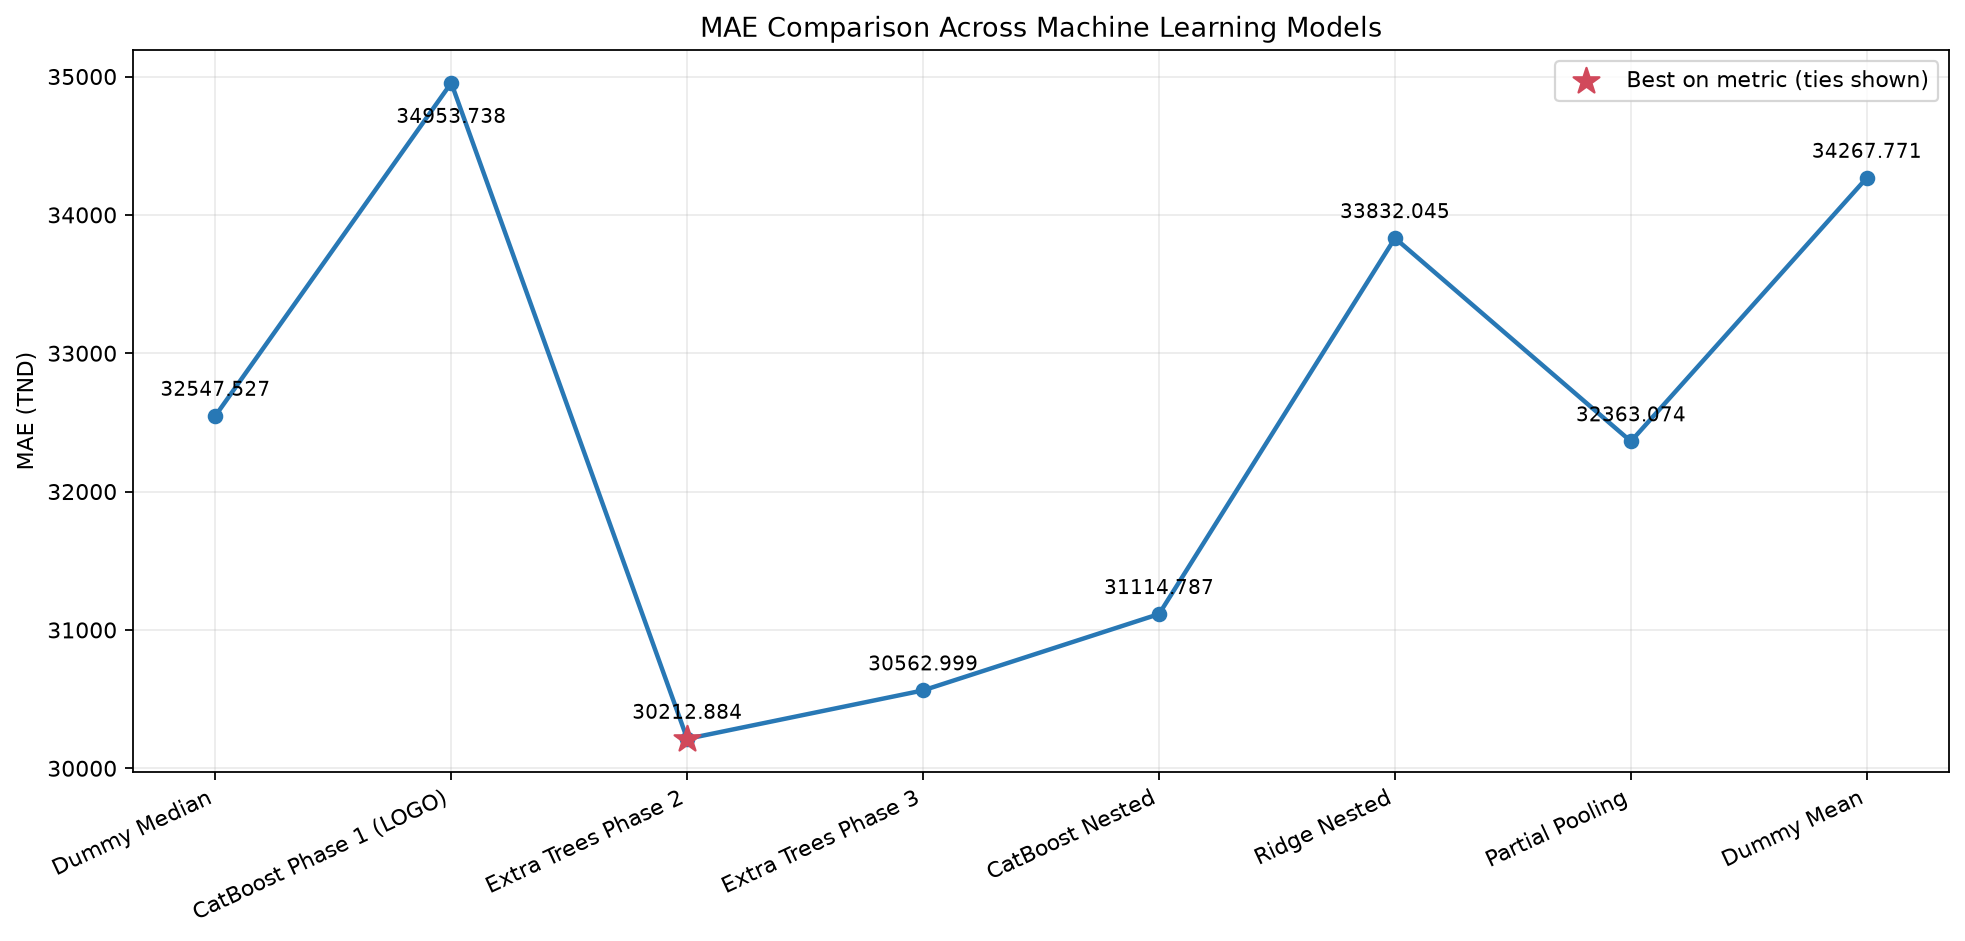

In [ ]:
render_metric_chart("MAE_TND","MAE (TND)","MAE Comparison Across Machine Learning Models","comparison_mae.png",False)


## RMSE Comparison


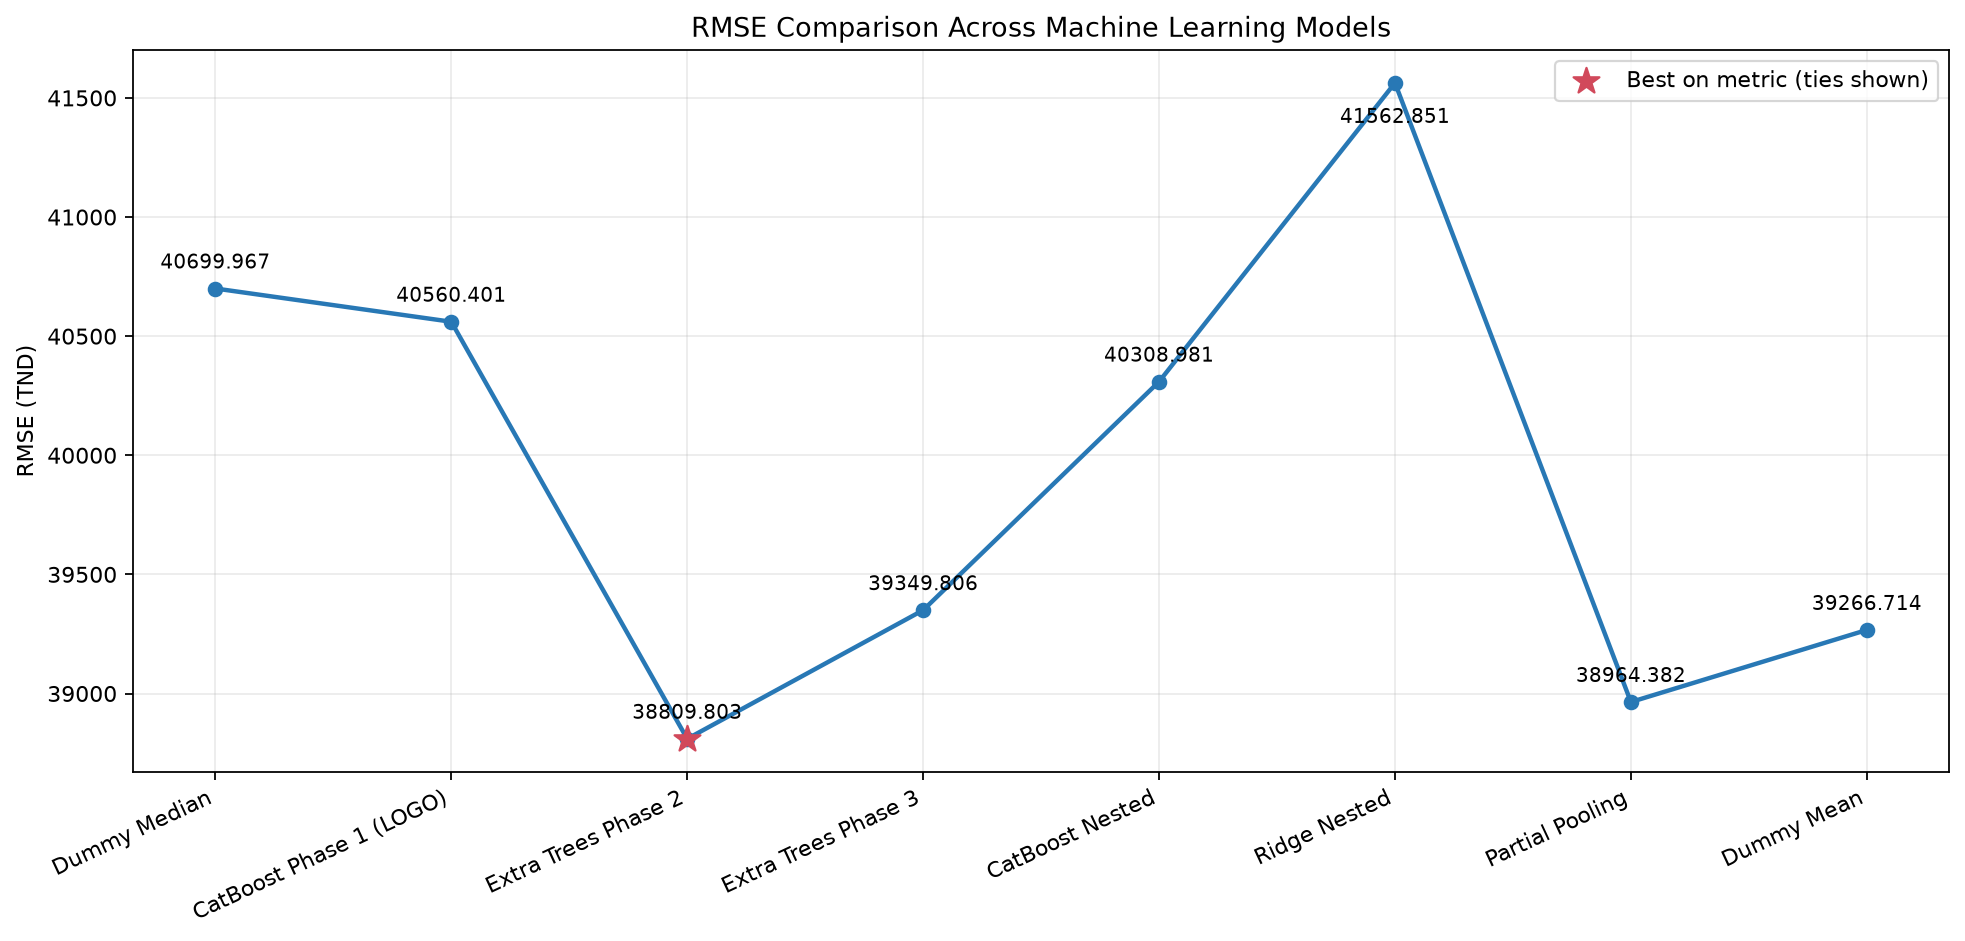

In [ ]:
render_metric_chart("RMSE_TND","RMSE (TND)","RMSE Comparison Across Machine Learning Models","comparison_rmse.png",False)


## R2 Comparison


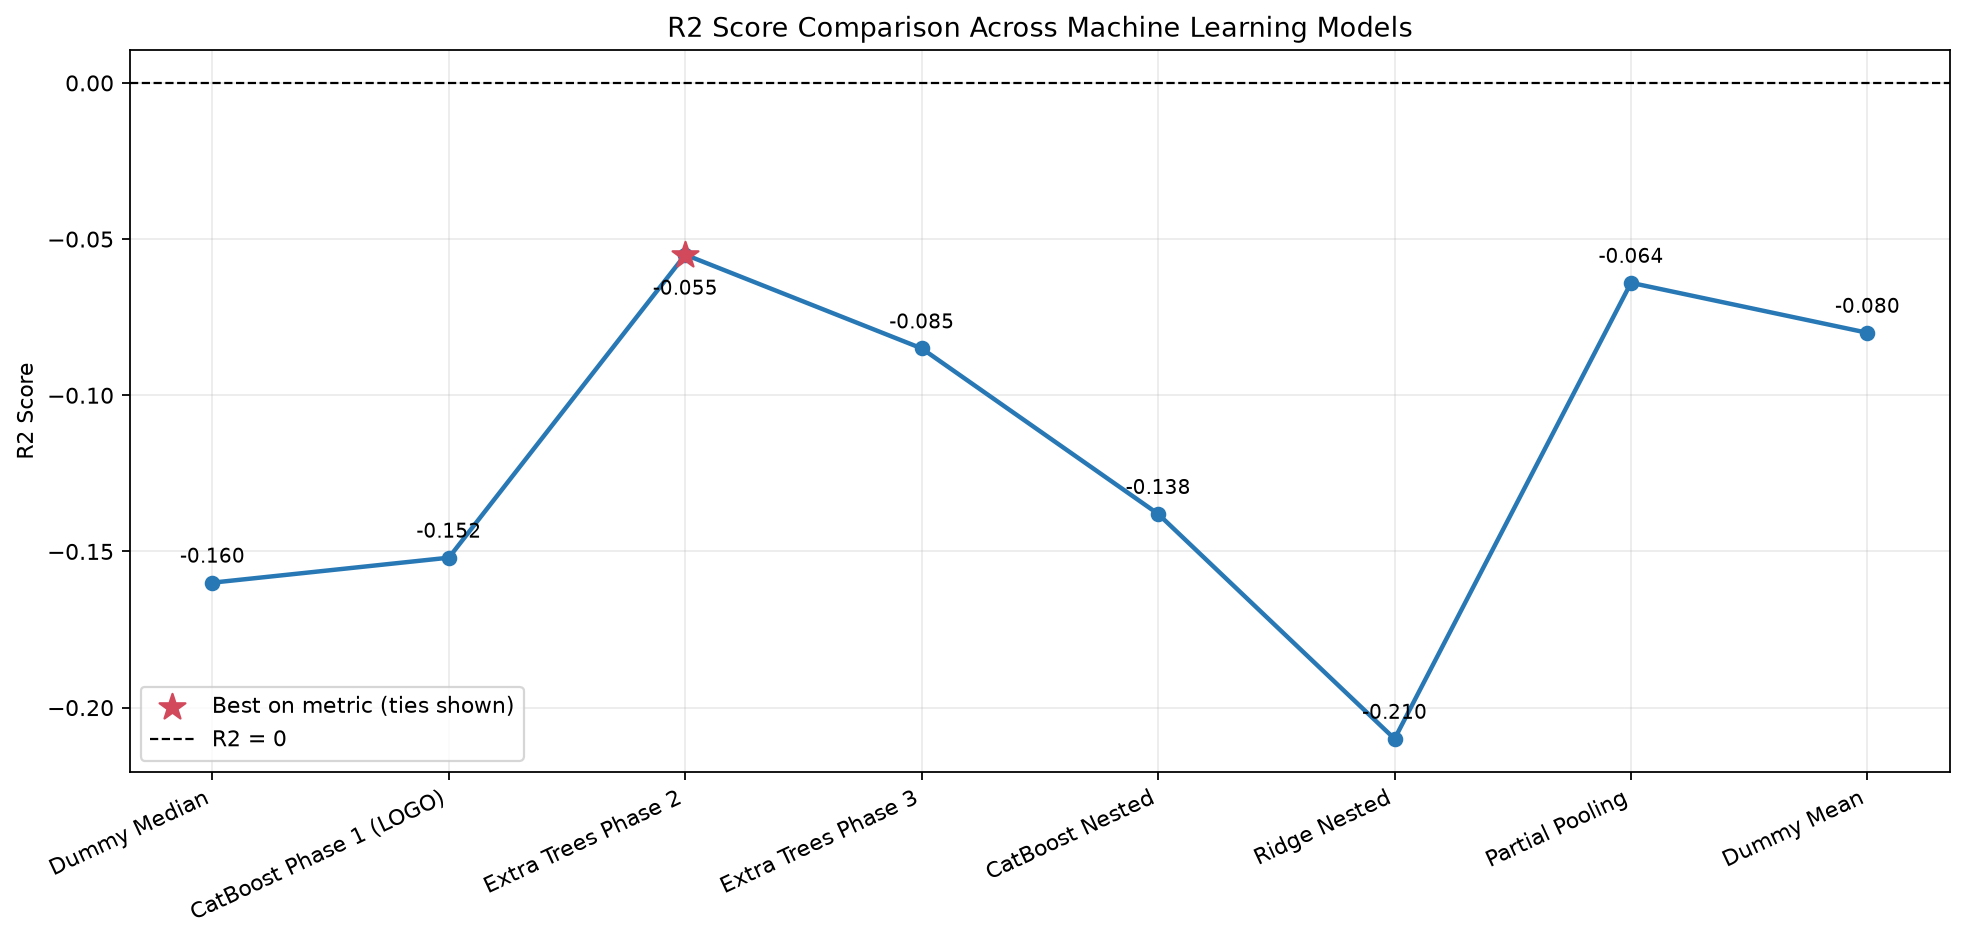

In [ ]:
render_metric_chart("R2","R2 Score","R2 Score Comparison Across Machine Learning Models","comparison_r2.png",True)


## Accuracy +/-10% Comparison


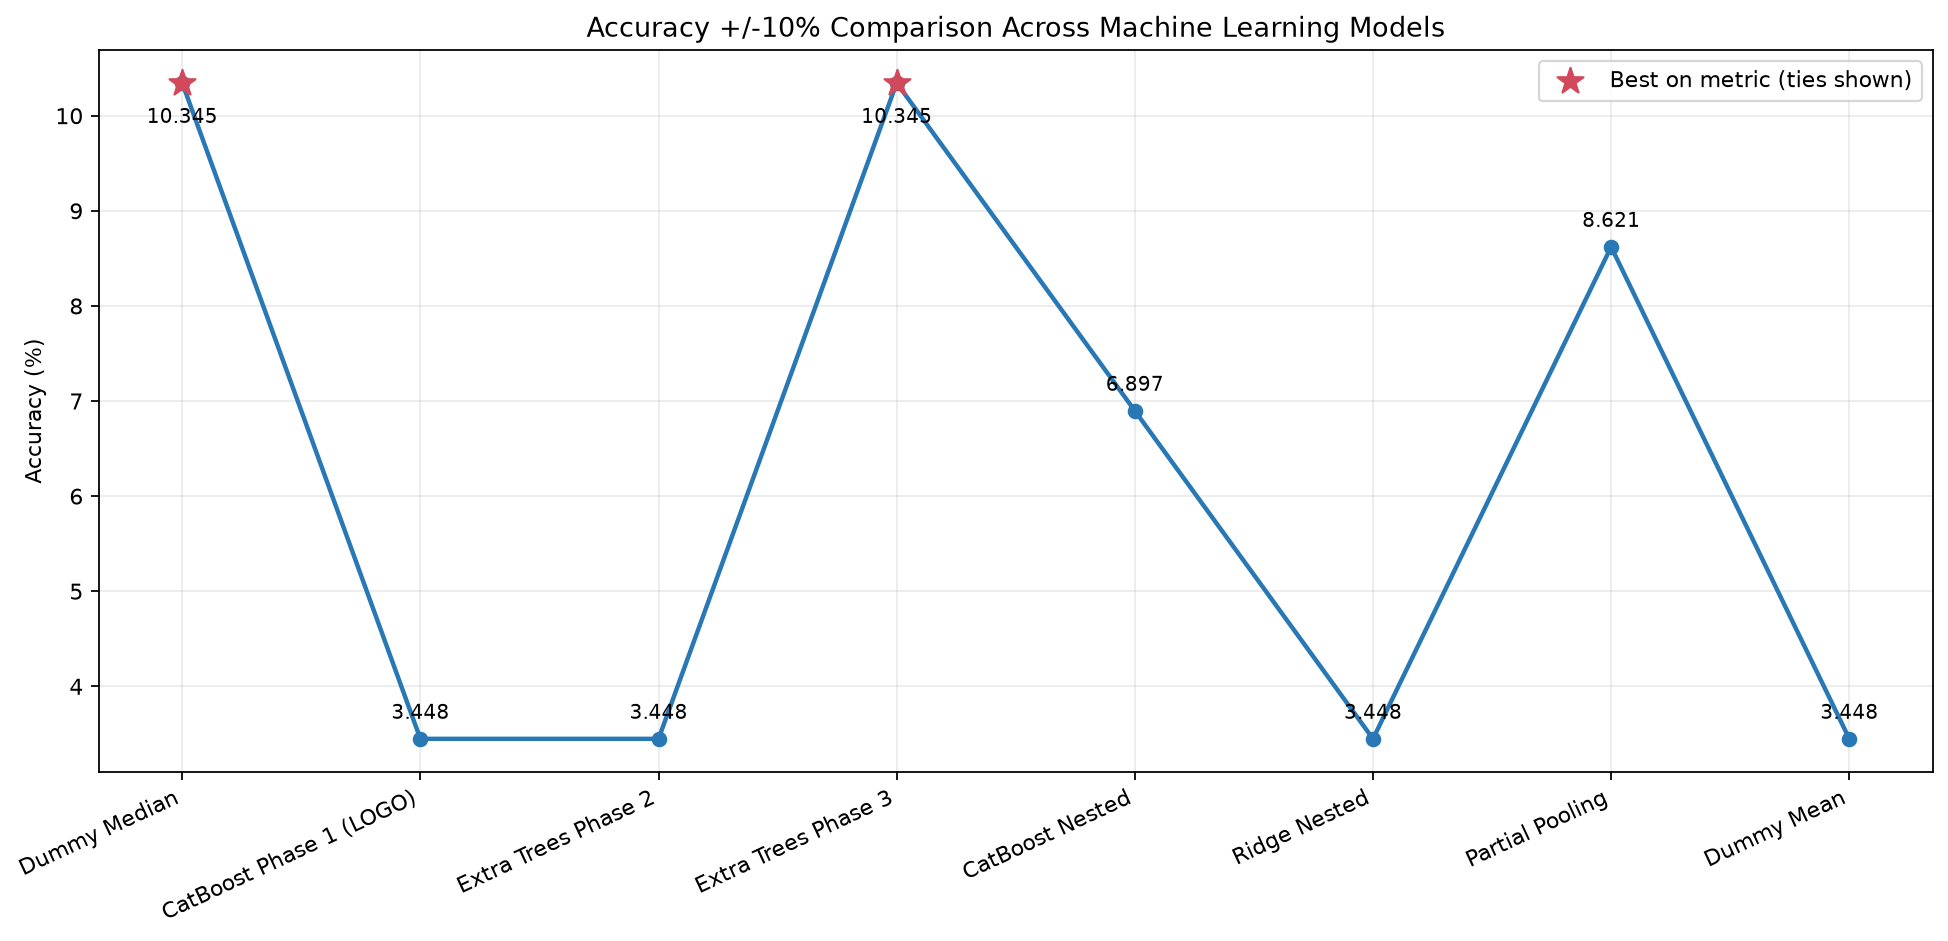

In [ ]:
render_metric_chart("Acc_10_pct","Accuracy (%)","Accuracy +/-10% Comparison Across Machine Learning Models","comparison_accuracy.png",True)
